# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [97]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [98]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [99]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [100]:
import random

numbers = list(range(10))

#Двічі ДО set_seed()
print("Дo set_seed():")

print("randint:", random.randint(1, 100))

numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

print("randint:", random.randint(1, 100))

numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)


# Двічі після set_seed(),
print("\nПісля set_seed() перед кожною генерацією:")

set_seed()
print("randint:", random.randint(1, 100))

set_seed()
print("randint:", random.randint(1, 100))


set_seed()
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)


# 3. Двічі без проміжного set_seed()
print("\nПісля одного set_seed(), без проміжного:")

set_seed()

print("randint:", random.randint(1, 100))
print("randint:", random.randint(1, 100))

numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

Дo set_seed():
randint: 90
shuffle: [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]
randint: 44
shuffle: [5, 7, 1, 9, 0, 8, 6, 3, 2, 4]

Після set_seed() перед кожною генерацією:
randint: 82
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

Після одного set_seed(), без проміжного:
randint: 82
randint: 15
shuffle: [7, 5, 2, 8, 9, 6, 1, 3, 4, 0]
shuffle: [5, 3, 2, 8, 4, 6, 7, 1, 9, 0]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [101]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [102]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [103]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("Масив форми 3х4 заповнений нулями")
print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print("\nМасив форми 3х4 заповнений числом 7")
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


Масив форми 3х4 заповнений нулями
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64

Масив форми 3х4 заповнений числом 7
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [104]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print("Від 0 до 20 з кроком 2")
print(arange_arr)
print("З 5 рівномірно розподілених точок від 0 до 1")
print(linspace_arr)


Від 0 до 20 з кроком 2
[ 0  2  4  6  8 10 12 14 16 18]
З 5 рівномірно розподілених точок від 0 до 1
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [105]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Одинична матриця 4х4")
print(identity)
print("Випадковий масив чисел 3х3 у діапазоні [0, 10)")
print(random_ints)


Одинична матриця 4х4
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Випадковий масив чисел 3х3 у діапазоні [0, 10)
[[6 3 7]
 [4 6 9]
 [2 6 7]]


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [106]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [107]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [108]:
df = pd.DataFrame({
    "name": ["Віталій", "Назарій", "Юрій", "Василь"],
    "score": [91, 84, 67, 88]
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"]>80].sort_values("score", ascending=False)
print(top)


      name  score
0  Віталій     91
3   Василь     88
1  Назарій     84


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [109]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.select(
    [
        df["score"] >= 90,
        df["score"] >= 75,
    ],
    [
        "A",
        "B"
    ],
    default = "C"
)
print(df)


      name  score grade
0  Віталій     91     A
1  Назарій     84     B
2     Юрій     67     C
3   Василь     88     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [110]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t =  torch.full((2, 3), 7)

print("Тензор форми 2х3, заповнений нулями")
print(zeros_t)
print("\nТензор форми 2х3, заповнений числом 7")
print(sevens_t)


Тензор форми 2х3, заповнений нулями
tensor([[0., 0., 0.],
        [0., 0., 0.]])

Тензор форми 2х3, заповнений числом 7
tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [111]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print("Тензор від 0 до 20 із кроком 2")
print(arange_t)
print("\nТензор із 5 рівномірно розподілених точок від 0 до 1")
print(linspace_t)


Тензор від 0 до 20 із кроком 2
tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

Тензор із 5 рівномірно розподілених точок від 0 до 1
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [112]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print("Тензор напряму зі списку")
print(from_list)
print("shape: ", from_list.shape)
print("dtype: ", from_list.dtype)
print("ndim: ", from_list.ndim)
print("Випадковий тензор 3х3")
print(random_t)
print("shape: ", random_t.shape)
print("dtype: ", random_t.dtype)
print("ndim: ", random_t.ndim)


Тензор напряму зі списку
tensor([[1, 2],
        [3, 4]])
shape:  torch.Size([2, 2])
dtype:  torch.int64
ndim:  2
Випадковий тензор 3х3
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
shape:  torch.Size([3, 3])
dtype:  torch.float32
ndim:  2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [113]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний: ", x.grad.item())

gradient = 2 * x.item()
print("Аналітичний: ",gradient)

Автоматичний:  10.0
Аналітичний:  10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [114]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

for _ in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()
  with torch.no_grad(): x -= lr * x.grad
  x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

In [115]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

In [116]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [117]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

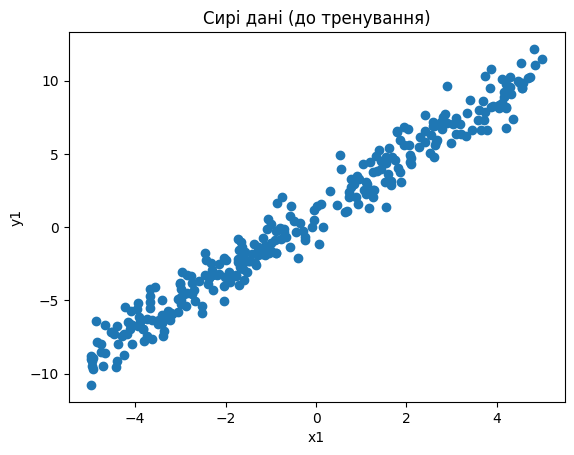

In [118]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [119]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
indices = torch.randperm(TASK1_N)

x1_shuffled = x1[indices]
y1_shuffled = y1[indices]

train_size = int(0.7 * TASK1_N)
val_size = int(0.15 * TASK1_N)

x_train1 = x1_shuffled[:train_size]
y_train1 = y1_shuffled[:train_size]

x_val1 = x1_shuffled[train_size:train_size + val_size]
y_val1 = y1_shuffled[train_size:train_size + val_size]

x_test1 = x1_shuffled[train_size + val_size:]
y_test1 = y1_shuffled[train_size + val_size:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [120]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


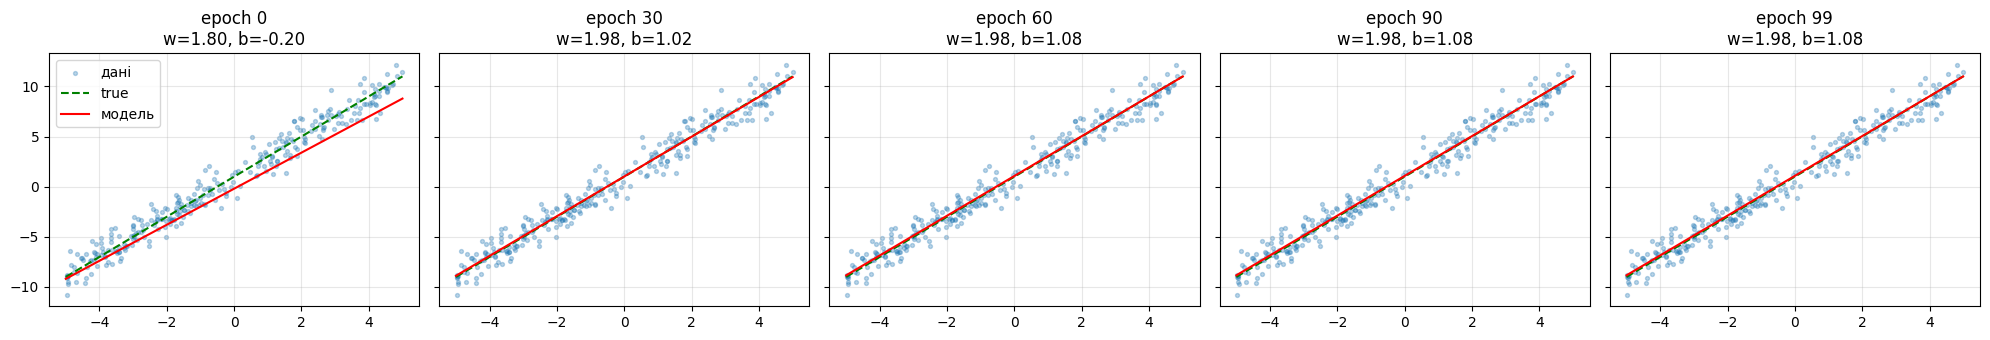

In [121]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Власний сценарій: години сну → продуктивність

Уявімо, що ми хочемо змоделювати залежність продуктивності людини від кількості годин сну за ніч.

Нехай:
- `x` - кількість годин сну;
- `y` - умовний індекс продуктивності від 0 до 100.

Для моделі візьмемо лінійну залежність:

`y = 8 * x + 20 + ε`

Тобто `w = 8`, а `b = 20`.

Такі значення здаються правдоподібними для напів-реального сценарію: зі збільшенням кількості сну продуктивність у середньому зростає. Наприклад, при 6 годинах сну очікуваний індекс становитиме приблизно 68, а при 8 годинах - приблизно 84.

Звичайно, реальна продуктивність залежить не тільки від сну, тому додаємо випадковий шум `ε`, який моделює інші фактори.

Генерація даних

In [122]:
import torch
import pandas as pd

CUSTOM_W = 8.0
CUSTOM_B = 20.0
CUSTOM_N = 300

# Години сну: від 4 до 10 годин
x_custom = torch.empty(CUSTOM_N, 1).uniform_(4, 10)

# Випадковий шум
noise_custom = 5.0 * torch.randn(CUSTOM_N, 1)

# Продуктивність
y_custom = CUSTOM_W * x_custom + CUSTOM_B + noise_custom

print("Кількість точок:", CUSTOM_N)
print("x min/max:", x_custom.min().item(), x_custom.max().item())

Кількість точок: 300
x min/max: 4.032970905303955 9.990741729736328


Збереження у CSV

In [123]:
df_custom = pd.DataFrame({
    "sleep_hours": x_custom.squeeze().numpy(),
    "productivity": y_custom.squeeze().numpy()
})

df_custom.to_csv("dataset.csv", index=False)

print("Дані збережено у dataset.csv")
df_custom.head()

Дані збережено у dataset.csv


,sleep_hours,productivity
0,6.054425,76.881729
1,8.809938,87.330910
2,5.897040,61.769268
3,6.742368,71.836349
4,9.801215,90.641983


Перемішування і train/val/test

In [124]:
indices = torch.randperm(CUSTOM_N)

x_custom = x_custom[indices]
y_custom = y_custom[indices]

train_size = int(0.70 * CUSTOM_N)
val_size = int(0.15 * CUSTOM_N)
test_size = CUSTOM_N - train_size - val_size

x_train = x_custom[:train_size]
y_train = y_custom[:train_size]

x_val = x_custom[train_size:train_size + val_size]
y_val = y_custom[train_size:train_size + val_size]

x_test = x_custom[train_size + val_size:]
y_test = y_custom[train_size + val_size:]

print(f"train/val/test: {len(x_train)}/{len(x_val)}/{len(x_test)}")

train/val/test: 210/45/45


Функції для навчання

In [125]:
import torch.nn as nn

def train_model(model, x_train, y_train, x_val, y_val, epochs=1000, lr=0.01):
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()

        predictions = model(x_train)
        train_loss = criterion(predictions, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_predictions = model(x_val)
            val_loss = criterion(val_predictions, y_val)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

    return train_losses, val_losses


def evaluate_model(model, x_test, y_test):
    model.eval()

    with torch.no_grad():
        predictions = model(x_test)
        mse = nn.MSELoss()(predictions, y_test)

    return mse.item()

Створення та тренування моделі

In [126]:
model_custom = nn.Linear(1, 1)

train_losses, val_losses = train_model(
    model_custom,
    x_train,
    y_train,
    x_val,
    y_val,
    epochs=1000,
    lr=0.01
)

test_loss = evaluate_model(
    model_custom,
    x_test,
    y_test
)

print("Test MSE:", test_loss)

Test MSE: 24.697479248046875


Подивитися, що модель вивчила

In [127]:
learned_w = model_custom.weight.item()
learned_b = model_custom.bias.item()

print(f"Справжній w: {CUSTOM_W:.2f}")
print(f"Вивчений w:  {learned_w:.2f}")

print(f"Справжній b: {CUSTOM_B:.2f}")
print(f"Вивчений b:  {learned_b:.2f}")

Справжній w: 8.00
Вивчений w:  8.94
Справжній b: 20.00
Вивчений b:  13.42


Графік результату

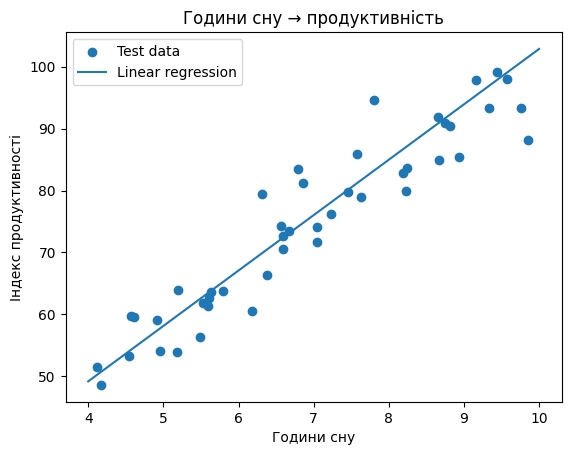

In [128]:
import matplotlib.pyplot as plt

plt.scatter(x_test, y_test, label="Test data")

x_line = torch.linspace(4, 10, 100).reshape(-1, 1)

with torch.no_grad():
    y_line = model_custom(x_line)

plt.plot(x_line, y_line, label="Linear regression")

plt.xlabel("Години сну")
plt.ylabel("Індекс продуктивності")
plt.title("Години сну → продуктивність")
plt.legend()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [129]:
torch.save(model_custom.state_dict(),  f"{ARTIFACT_DIR}/model.pt")

print("Модель збережено у Google Drive: model.pt")

Модель збережено у Google Drive: model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [130]:
!pip install -q gradio
import gradio as gr

Завантаження збереженої моделі

In [131]:
import torch
import torch.nn as nn

model_loaded = nn.Linear(1, 1)

model_loaded.load_state_dict(
    torch.load(
        f"{ARTIFACT_DIR}/model.pt",
        map_location="cpu"
    )
)

model_loaded.eval()

print("Модель успішно завантажена")

Модель успішно завантажена


Функція прогнозування

In [132]:
def predict_productivity(sleep_hours):
    x = torch.tensor([[sleep_hours]], dtype=torch.float32)

    with torch.no_grad():
        prediction = model_loaded(x)

    return prediction.item()

Створення інтерактивної апки

In [133]:
app = gr.Interface(
    fn=predict_productivity,
    inputs=gr.Number(
        label="Кількість годин сну",
        value=8
    ),
    outputs=gr.Number(
        label="Прогнозований індекс продуктивності"
    ),
    title="Прогноз продуктивності",
    description="Введіть кількість годин сну, щоб отримати прогнозований індекс продуктивності."
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e7652bee4fe0b726db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```